# Analysis of the guest demand distribution

The main question is which distribution is most suitable to model the guest visit times given the emperical data?

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import ast
import numpy as np
import scipy.stats as stats
import openturns as ot
from math import ceil

In [9]:
filename = Path('./data/processed/20210818_evening_guest_demand.csv')
dtypes = {'group_size': 'int', 'fully_captured': 'bool', 'visit_time': 'float'}
df = pd.read_csv(filename, dtype=dtypes, parse_dates=['start_time', 'end_time'])

visit_times = np.array((df['end_time'] - df['start_time'])/np.timedelta64(1, 's'))
visit_times = visit_times[~np.isnan(visit_times)] 


### Plot histogram for several bin counts

The plot shows that, regardless of the bin count:
- the visit times range from 339 seconds (5.65 minutes) to 13413 seconds  (03:43:33 [hh:mm:ss])

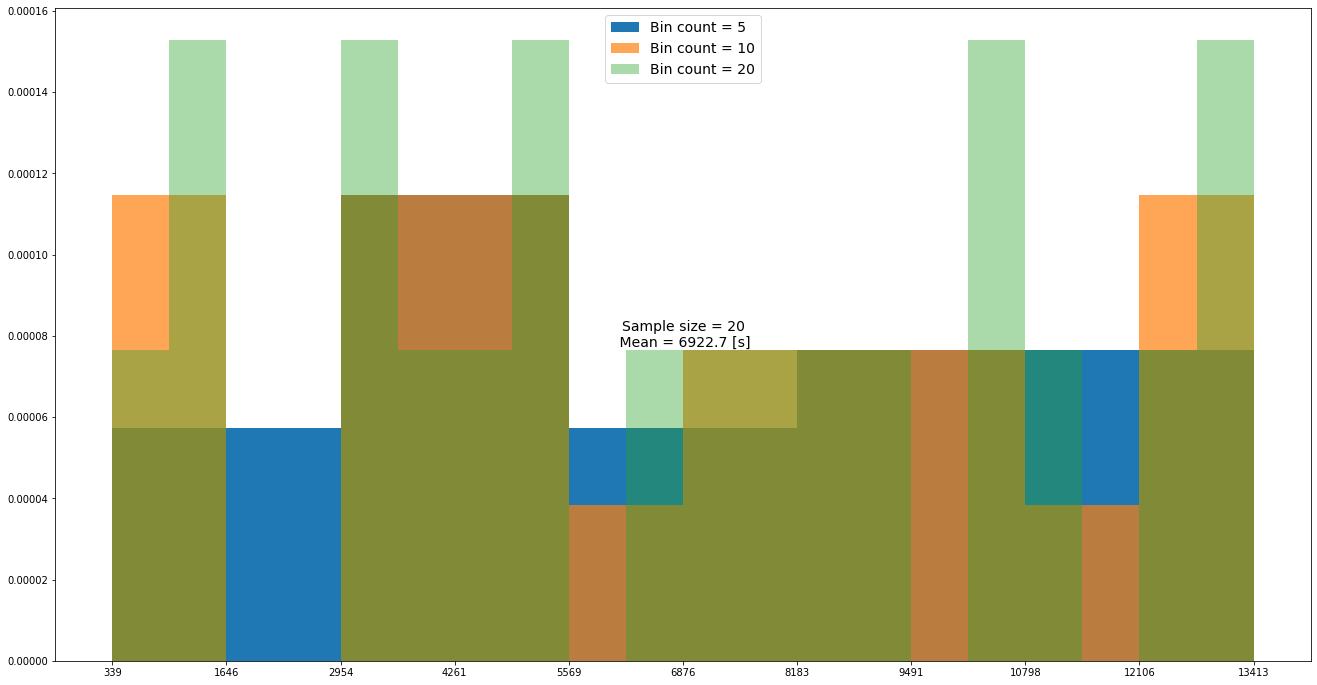

In [10]:
plt.rcParams['figure.figsize'] = [22.5,12]

bin_counts = [5, 10, 20]
alpha_step = 0.6/(len(bin_counts) - 1)
for ii, bin_count in enumerate(bin_counts):
    hist = plt.hist(visit_times, bins=bin_count, density=True, label=f'Bin count = {bin_count}', alpha=1-ii*alpha_step)
    if ii == 1:
        x = hist[1]

plt.xticks(x)
plt.text(0.5,0.5, f'Sample size = {len(visit_times)}\n Mean = {np.mean(visit_times):.1f} [s]', horizontalalignment='center', verticalalignment='center', transform = plt.gca().transAxes, fontsize=14)
leg = plt.legend(fontsize=14)

### Fit the openturns distributions and determine the goodness-of-fit of the different fitted distributions

In [15]:
%%capture --no-stdout

list_of_dists = [nm for nm, _ in stats._distr_params.distcont]
scipy_2_ot_distr = {
    'arcsine': 'ArcsineFactory',
    'beta': 'BetaFactory',
    'burr': 'BurrFactory',
    'chi': 'ChiFactory',
    'chi2': 'ChiSquareFactory',
    'expon': 'ExponentialFactory',
    'invweibull': 'FrechetFactory',
    'gamma': 'GammaFactory',
    'pareto': 'ParetoFactory',
    'genpareto': 'GeneralizedParetoFactory',
    'weibull_max': 'WeibullMaxFactory',
    'genextreme': 'GeneralizedExtremeValueFactory',
    'gumbel_r': 'GumbelFactory',
    'invgauss': 'InverseNormalFactory',
    'laplace': 'LaplaceFactory',
    'logistic': 'LogisticFactory',
    'lognorm': 'LogNormalFactory',
    'loguniform': 'LogUniformFactory',
    'norm': 'NormalFactory',
    'rayleigh': 'RayleighFactory',
    't': 'StudentFactory',
    'trapezoid': 'TrapezoidalFactory',
    'truncnorm': 'TruncatedNormalFactory',
    'uniform': 'UniformFactory',
    'vonmises': 'VonMisesFactory',
    'weibull_min': 'WeibullMinFactory',
}

min_value = min(visit_times)
max_value = max(visit_times)    

visit_times_ot = ot.Sample(np.expand_dims(visit_times, axis=1))

results = []

for stat_name in list_of_dists:
    dist = getattr(stats, stat_name)
    try:
        scipy_params = dist.fit(visit_times)
        scipy_res = stats.cramervonmises(visit_times, stat_name, args=scipy_params)
        scipy_cvm_p_val = scipy_res.pvalue
    except:
        print(f'Could not fit {stat_name}')
        continue
    if stat_name in scipy_2_ot_distr:
        factory = getattr(ot, scipy_2_ot_distr[stat_name])
        try:
            ot_dist = factory().build(visit_times_ot)
        except:
            ot_cvm_p_val = -1
            ot_dist = None
            continue
        
        ot_res = stats.cramervonmises_2samp(visit_times, np.array(ot_dist.getSample(1000000)).flatten())
        ot_cvm_p_val = ot_res.pvalue
        try:
            truncated = ot.TruncatedDistribution(ot_dist, min_value, max_value)
            ot_res = stats.cramervonmises_2samp(visit_times, np.array(truncated.getSample(1000000)).flatten())
            ot_trunc_cvm_p_val = ot_res.pvalue
            ot_trunc_dist = truncated      
        except:
            #print(distr_data[0])
            ot_trunc_cvm_p_val = -1
            ot_trunc_dist = None 
    else:
        ot_cvm_p_val = -1
        ot_dist = None
        ot_trunc_cvm_p_val = -1
        ot_trunc_dist = None      
    results.append((stat_name, ot_trunc_cvm_p_val, ot_cvm_p_val, scipy_cvm_p_val, ot_trunc_dist, ot_dist, scipy_params))
        
results.sort(key=lambda el: (el[1], el[2], el[3]), reverse=True) 
    

Could not fit kstwo


### Plots showing the fit of the distributions, truncated using a minimum an maximum value based on the data

The plots below show all the continuous distributions from the scipy package which could be fitted to the data. Per plot the following elements are shown:
1. The distribution of the data in the form of histograms using different bin counts
2. The pdf of the fitted scipy distribution
3. If available the pdf of the fitted openturn distribution
4. If available the pdf of the truncated version of the fitted openturn distribution
5. The p-value obtained using the Cramer-von-mises test indicating how well the distribution obtained using scipy fits the data (If p < 0.05 the null hypothesis that the distributions are drawn form the same "parent distribution "can be rejected at a 95% confidence level, i.e. the higher this value the better the fit)
6. The p-value obtained using the Cramer-von-mises test indicating how well the distribution obtained using openturns fits the data
7. The p-value obtained using the Cramer-von-mises test indicating how well the truncated distribution obtained using openturns fits the data
8. The Pearson's rank correlation value. This one was used by Yufei to estimate the fit and the sam method has been use here. However, firstly, as this is based on the fit of only 10 data points which makes it sensitive to the choice of these 10 points (they are extracted from the histogram) and secondly, the plots show it cannot make a clear distinction between the fit of the different distributions

The plot are sorted in order of 1) the p-value of the truncated distribution, 2) the p-value of the openturns distribution and 3) the p-value of the scipy distribution

Based on the plots a conclusion is drawn on which distributions form the best candidates for use in the model. This can be found below the plots.



C:\Users\martijnsparnaa\Anaconda3\envs\nomad_experiments\lib\site-packages\scipy\stats\_continuous_distns.py:105: RuntimeWarning: floating point number truncated to an integer
  return -scu._smirnovp(n, x)
C:\Users\martijnsparnaa\Anaconda3\envs\nomad_experiments\lib\site-packages\scipy\stats\_continuous_distns.py:2804: RuntimeWarning: The shape parameter of the erlang distribution has been given a non-integer value array(339050.52449144).
  warnings.warn(
C:\Users\martijnsparnaa\Anaconda3\envs\nomad_experiments\lib\site-packages\scipy\stats\_continuous_distns.py:6893: RuntimeWarning: divide by zero encountered in power
  return c*_norm_pdf(x) * (_norm_cdf(-x)**(c-1.0))
C:\Users\martijnsparnaa\Anaconda3\envs\nomad_experiments\lib\site-packages\scipy\stats\_continuous_distns.py:6893: RuntimeWarning: invalid value encountered in multiply
  return c*_norm_pdf(x) * (_norm_cdf(-x)**(c-1.0))
C:\Users\martijnsparnaa\Anaconda3\envs\nomad_experiments\lib\site-packages\scipy\stats\_continuous_dis

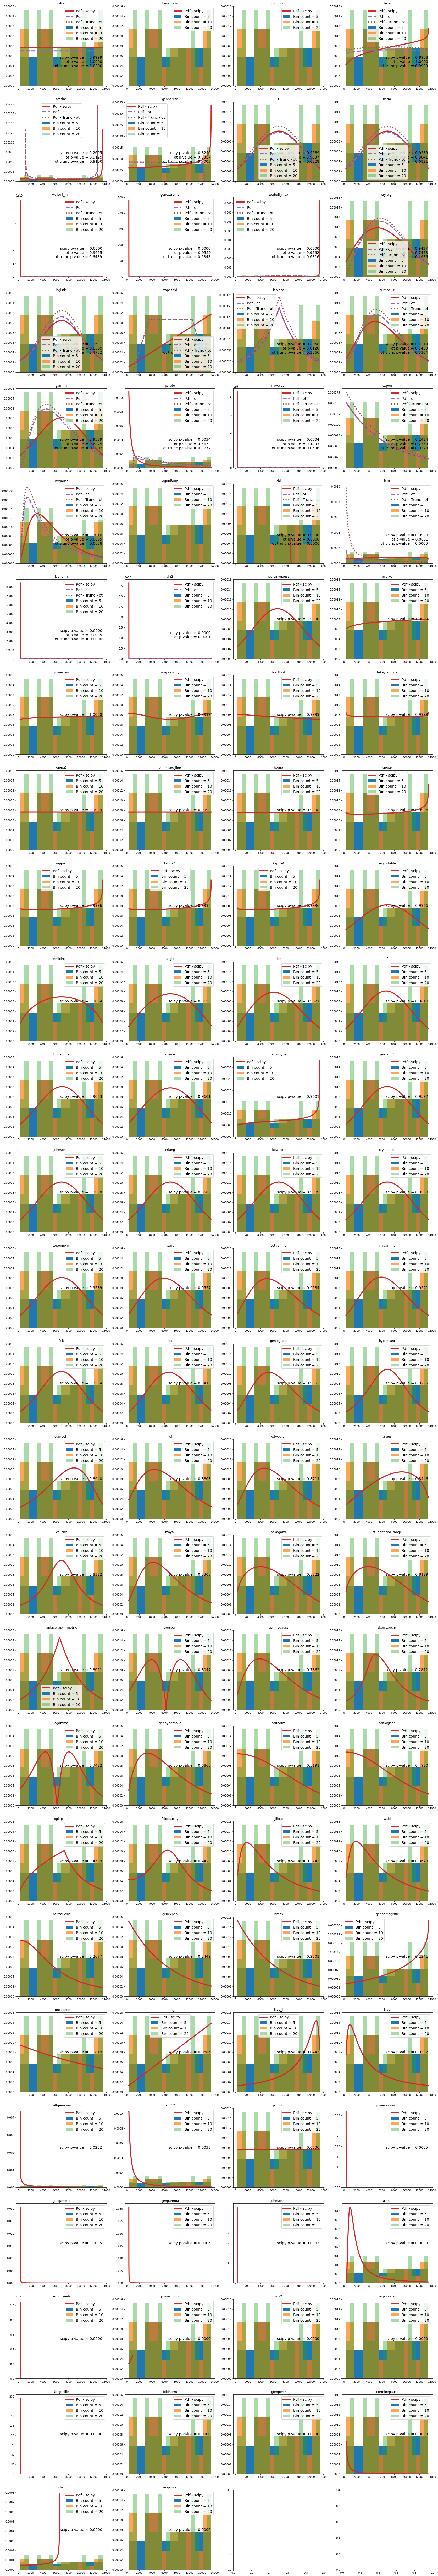

In [17]:
plt.rcParams['figure.figsize'] = [28.5,180]

col_count = 4
row_count = int(ceil(len(results)/col_count))
_, axes = plt.subplots(row_count, col_count)

axes = axes.flatten()

import scipy.stats as stats

min_value = min(visit_times)
max_value = max(visit_times)

for ii, distr_data in enumerate(results):
    stat_name, ot_trunc_cvm_p_val, ot_cvm_p_val, scipy_cvm_p_val, ot_trunc_dist, ot_dist, scipy_params = distr_data
    for jj, bin_count in enumerate(bin_counts):
        hist = axes[ii].hist(visit_times, bins=bin_count, density=True, label=f'Bin count = {bin_count}', alpha=1-jj*alpha_step)
    
    dist = getattr(stats, stat_name)(*scipy_params)
    x = np.arange(max(min_value, dist.ppf(0)), min(max_value,dist.ppf(1)), 10)
    x_ot = ot.Sample(np.expand_dims(x, axis=1))
    axes[ii].plot(x, dist.pdf(x), linewidth=4, label='Pdf - scipy')
    if ot_dist is not None:
        try:
            axes[ii].plot(x, np.array(ot_dist.computePDF(x_ot)), linewidth=4, linestyle='--', label='Pdf - ot')
            if ot_trunc_dist is not None:
                axes[ii].plot(x, np.array(ot_trunc_dist.computePDF(x_ot)), linewidth=4, linestyle=':', label='Pdf - Trunc - ot')
                axes[ii].text(0.95,0.3, f'scipy p-value = {scipy_cvm_p_val:.4f}\n ot p-value = {ot_cvm_p_val:.4f}\n ot trunc p-value = {ot_trunc_cvm_p_val:.4f}', horizontalalignment='right', verticalalignment='center', transform = axes[ii].transAxes, fontsize=14)
            else:
                axes[ii].text(0.95,0.3, f'scipy p-value = {scipy_cvm_p_val:.4f}\n ot p-value = {ot_cvm_p_val:.4f}', horizontalalignment='right', verticalalignment='center', transform = axes[ii].transAxes, fontsize=14)
        except:
            pass
    else:
        axes[ii].text(0.95,0.5, f'scipy p-value = {scipy_cvm_p_val:.4f}', horizontalalignment='right', verticalalignment='center', transform = axes[ii].transAxes, fontsize=14)
    axes[ii].set_title(f'{stat_name}')
    leg = axes[ii].legend(fontsize=14)